# Задание 2.2. Кластеризация книг

In [104]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import LabelEncoder

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud


from umap import UMAP

RANDOM_STATE = 42
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
print('Все библиотеки загружены')

Все библиотеки загружены


[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1000)>
[nltk_data] Error loading punkt: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1000)>
[nltk_data] Error loading wordnet: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1000)>


---
## Загрузка и EDA

In [105]:
df = pd.read_csv('data.csv') 

print('Размер датасета:', df.shape)
print('\nКолонки:')
print(df.dtypes)
df.head()

Размер датасета: (4657, 4)

Колонки:
index       int64
title      object
genre      object
summary    object
dtype: object


,index,title,genre,summary
0,0,Drowned Wednesday,fantasy,Drowned Wednesday is the first Trustee among ...
1,1,The Lost Hero,fantasy,"As the book opens, Jason awakens on a school ..."
2,2,The Eyes of the Overworld,fantasy,Cugel is easily persuaded by the merchant Fia...
3,3,Magic's Promise,fantasy,The book opens with Herald-Mage Vanyel return...
4,4,Taran Wanderer,fantasy,Taran and Gurgi have returned to Caer Dallben...


In [106]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'count': missing, '%': missing_pct})

,count,%
index,0,0.0
title,0,0.0
genre,0,0.0
summary,0,0.0


Уникальных жанров: 10
genre
thriller      1023
fantasy        876
science        647
history        600
horror         600
crime          500
romance        111
psychology     100
sports         100
travel         100
Name: count, dtype: int64


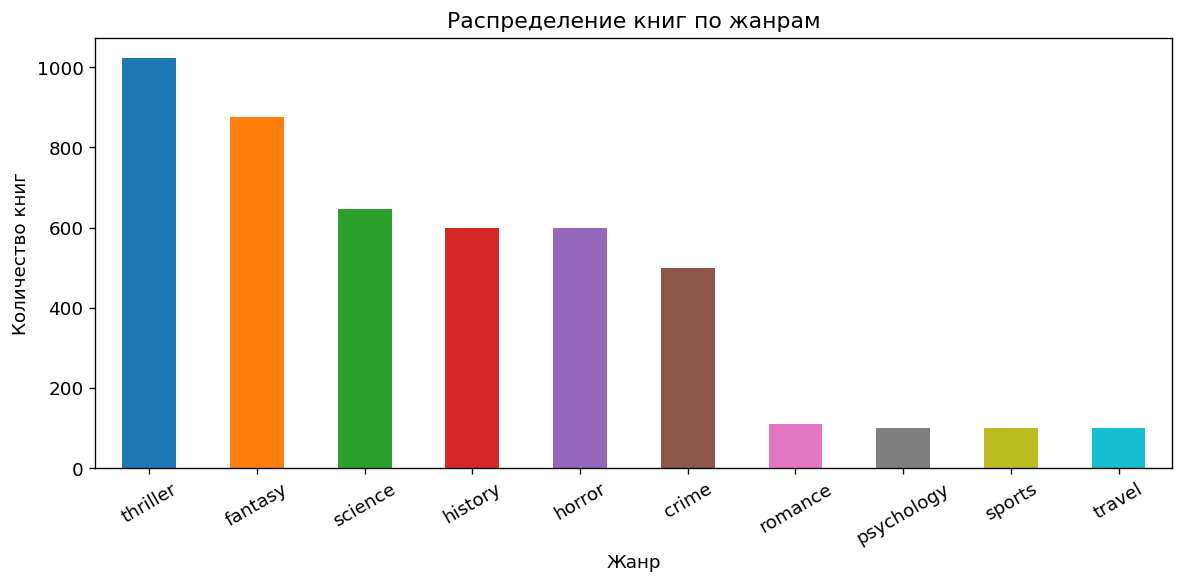

In [107]:
genre_col = 'genre'  

genre_counts = df[genre_col].value_counts()
print(f'Уникальных жанров: {genre_counts.shape[0]}')
print(genre_counts)

fig, ax = plt.subplots(figsize=(10, 5))
genre_counts.plot(kind='bar', ax=ax, color=sns.color_palette('tab10', len(genre_counts)))
ax.set_title('Распределение книг по жанрам')
ax.set_xlabel('Жанр')
ax.set_ylabel('Количество книг')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

count    4657.0
mean      359.1
std       437.6
min         1.0
25%       118.0
50%       193.0
75%       436.0
max      5663.0
Name: summary_len_words, dtype: float64


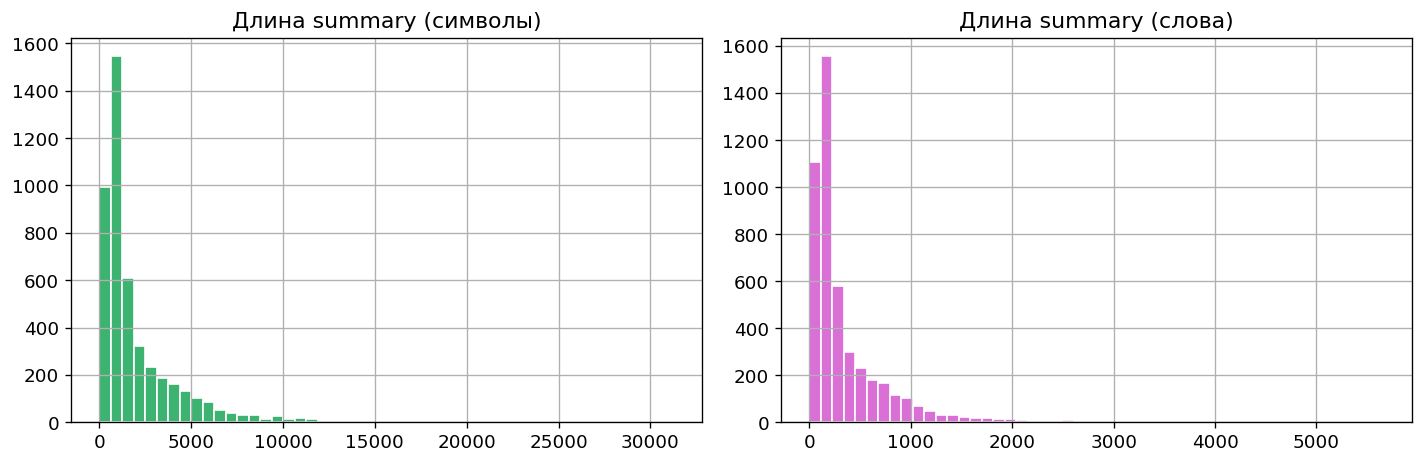

In [108]:
summary_col = 'summary'

if summary_col in df.columns:
    df['summary_len_chars'] = df[summary_col].fillna('').str.len()
    df['summary_len_words'] = df[summary_col].fillna('').str.split().str.len()

    print(df['summary_len_words'].describe().round(1))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    df['summary_len_chars'].hist(bins=50, ax=axes[0], color='mediumseagreen', edgecolor='white')
    axes[0].set_title('Длина summary (символы)')
    df['summary_len_words'].hist(bins=50, ax=axes[1], color='orchid', edgecolor='white')
    axes[1].set_title('Длина summary (слова)')
    plt.tight_layout()
    plt.show()

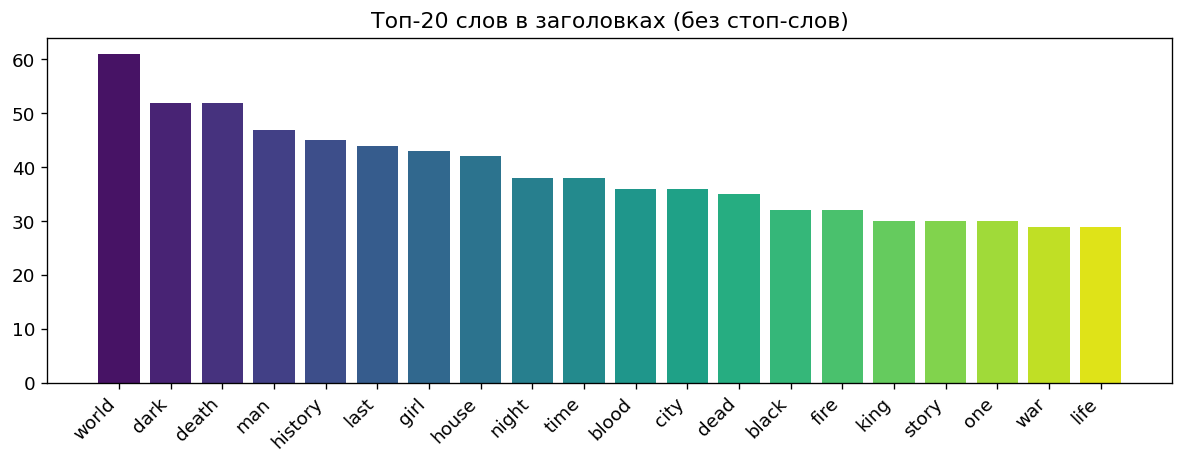

In [109]:
from itertools import chain

stop_en = set(stopwords.words('english'))
all_words = list(chain.from_iterable(
    t.lower().split() for t in df[title_col].dropna()
))
filtered_words = [w for w in all_words if w.isalpha() and w not in stop_en and len(w) > 2]
top_words = Counter(filtered_words).most_common(20)

words, freqs = zip(*top_words)
plt.figure(figsize=(10, 4))
plt.bar(words, freqs, color=sns.color_palette('viridis', 20))
plt.xticks(rotation=45, ha='right')
plt.title('Топ-20 слов в заголовках (без стоп-слов)')
plt.tight_layout()
plt.show()

---
## Предобработка данных и векторизация заголовков

In [110]:
import re

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text: str) -> str:
    #Нижний регистр, удаление спецсимволов, лемматизация, удаление стоп-слов.
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)   
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

# Удаляем строки с пустым заголовком или жанром
df_clean = df.dropna(subset=[title_col, genre_col]).copy()
df_clean['title_clean'] = df_clean[title_col].apply(clean_text)

# Убираем пустые заголовки после чистки
df_clean = df_clean[df_clean['title_clean'].str.strip().str.len() > 0].reset_index(drop=True)
print(f'Строк после очистки: {len(df_clean)}')
df_clean[['title', 'title_clean', genre_col]].head(8)

Строк после очистки: 4639


,title,title_clean,genre
0,Drowned Wednesday,drowned wednesday,fantasy
1,The Lost Hero,lost hero,fantasy
2,The Eyes of the Overworld,eye overworld,fantasy
3,Magic's Promise,magic promise,fantasy
4,Taran Wanderer,taran wanderer,fantasy
5,Thendara House,thendara house,fantasy
6,The Thief,thief,fantasy
7,The Sweet Far Thing,sweet far thing,fantasy


In [111]:
count_vec = CountVectorizer(
    max_features=5000,
    min_df=2,          # слово должно встречаться хотя бы в 2 документах
    max_df=0.95        # игнорируем слова, встречающиеся в >95% документов
)
X_count = count_vec.fit_transform(df_clean['title_clean'])
print(f'CountVectorizer: матрица {X_count.shape}')

tfidf_vec = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True   # логарифмическое сглаживание TF
)
X_tfidf = tfidf_vec.fit_transform(df_clean['title_clean'])
print(f'TfidfVectorizer:  матрица {X_tfidf.shape}')

CountVectorizer: матрица (4639, 1518)
TfidfVectorizer:  матрица (4639, 1518)


---
## Кластеризация k-средних: CountVectorizer vs TF-IDF

In [112]:
def reduce_2d(X, method='svd', n_components=2):
    # Снижение размерности до 2D для визуализации
    if method == 'svd':
        reducer = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
    elif method == 'umap' and HAS_UMAP:
        reducer = UMAP(n_components=n_components, random_state=RANDOM_STATE)
    else:
        reducer = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
    return reducer.fit_transform(X)


def top_terms_per_cluster(vectorizer, kmeans, n_terms=8):
    # Топ слова каждого кластера по расстоянию до центроида.
    terms = vectorizer.get_feature_names_out()
    result = {}
    order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
    for i in range(kmeans.n_clusters):
        result[i] = [terms[ind] for ind in order_centroids[i, :n_terms]]
    return result


def plot_clusters(coords, labels_cluster, labels_genre,
                  genre_names, title='Кластеры'):
    # 2 рядом: (a) раскраска по кластеру, (b) раскраска по жанру.
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    n_clusters = len(set(labels_cluster))
    palette = sns.color_palette('tab10', max(n_clusters, len(genre_names)))

    for ax, labels, col_labels, ttl in zip(
        axes,
        [labels_cluster, labels_genre],
        ['кластер', 'жанр'],
        [f'{title}: по кластерам', f'{title}: по жанрам']
    ):
        unique = sorted(set(labels))
        for i, lbl in enumerate(unique):
            mask = np.array(labels) == lbl
            lbl_name = genre_names[lbl] if col_labels == 'жанр' else f'K{lbl}'
            ax.scatter(coords[mask, 0], coords[mask, 1],
                       c=[palette[i % len(palette)]],
                       label=lbl_name, s=12, alpha=0.6)
        ax.set_title(ttl)
        ax.legend(markerscale=2, fontsize=8, loc='best',
                  ncol=2 if len(unique) > 6 else 1)
        ax.set_xlabel('Dim 1'); ax.set_ylabel('Dim 2')
    plt.tight_layout()
    plt.show()

print('Функции определены')

Функции определены


In [113]:
le = LabelEncoder()
genre_encoded = le.fit_transform(df_clean[genre_col])
genre_names = le.classes_
N_CLUSTERS = len(genre_names)   # 10 (или сколько есть в датасете)
print(f'Жанры ({N_CLUSTERS}):', genre_names)

Жанры (10): ['crime' 'fantasy' 'history' 'horror' 'psychology' 'romance' 'science'
 'sports' 'thriller' 'travel']


In [114]:
# KMeans + CountVectorizer 
km_count = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE,
                  n_init=10, max_iter=300)
labels_count = km_count.fit_predict(X_count)

sil_count = silhouette_score(X_count, labels_count, sample_size=3000,
                             random_state=RANDOM_STATE)
ari_count = adjusted_rand_score(genre_encoded, labels_count)

print('=== CountVectorizer + KMeans ===')
print(f'Silhouette Score : {sil_count:.4f}')
print(f'Adjusted Rand Index: {ari_count:.4f} ')

top_count = top_terms_per_cluster(count_vec, km_count)
for k, words in top_count.items():
    print(f'  Кластер {k:2d}: {", ".join(words)}')

=== CountVectorizer + KMeans ===
Silhouette Score : 0.0710
Adjusted Rand Index: 0.0000 
  Кластер  0: hunt, child, blood, red, time, killer, witch, great
  Кластер  1: body, guide, evidence, billion, agent, people, every, score
  Кластер  2: war, world, story, star, republic, commando, history, man
  Кластер  3: bone, city, map, terrifying, changed, story, modern, bag
  Кластер  4: last, jedi, love, every, secret, olympian, house, dark
  Кластер  5: man, one, search, mistook, ride, hat, world, running
  Кластер  6: dream, child, sleep, book, power, unlocking, team, fever
  Кластер  7: dragon, tattoo, girl, fortune, fog, folly, fool, foot
  Кластер  8: world, girl, death, dark, history, king, house, time
  Кластер  9: night, heat, fine, circus, long, watch, babylon, big


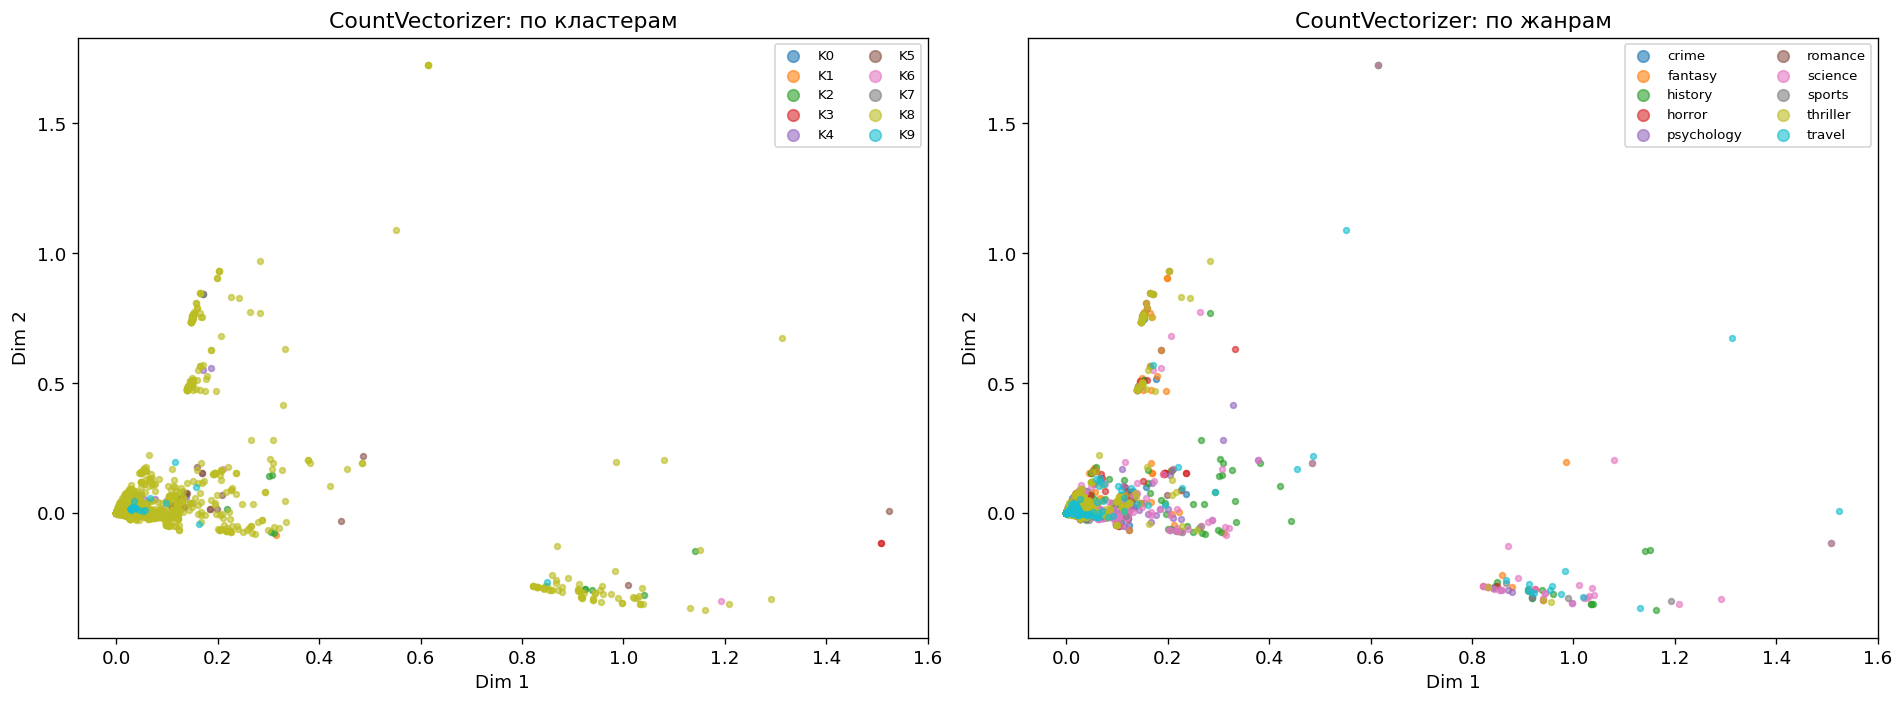

In [115]:
#  Визуализация Count кластеров (SVD → 2D) 
coords_count = reduce_2d(X_count, method='svd')
plot_clusters(coords_count, labels_count, genre_encoded,
              genre_names, title='CountVectorizer')

In [116]:
# KMeans + TF-IDF
km_tfidf = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE,
                  n_init=10, max_iter=300)
labels_tfidf = km_tfidf.fit_predict(X_tfidf)

sil_tfidf = silhouette_score(X_tfidf, labels_tfidf, sample_size=3000,
                              random_state=RANDOM_STATE)
ari_tfidf = adjusted_rand_score(genre_encoded, labels_tfidf)

print('=== TF-IDF + KMeans ===')
print(f'Silhouette Score : {sil_tfidf:.4f}')
print(f'Adjusted Rand Index: {ari_tfidf:.4f}')

top_tfidf = top_terms_per_cluster(tfidf_vec, km_tfidf)
for k, words in top_tfidf.items():
    print(f'  Кластер {k:2d}: {", ".join(words)}')

=== TF-IDF + KMeans ===
Silhouette Score : 0.0742
Adjusted Rand Index: 0.0019
  Кластер  0: life, secret, still, crow, brain, curious, henrietta, lack
  Кластер  1: girl, man, dark, world, house, king, last, star
  Кластер  2: darkness, wheel, light, hand, midnighters, colour, shall, tell
  Кластер  3: promise, winter, wind, magic, blood, death, junior, jedi
  Кластер  4: angel, demon, fallen, city, novel, ark, seeker, falling
  Кластер  5: court, starlight, wing, frost, ruin, air, chaos, burning
  Кластер  6: dead, book, speaker, zone, alive, city, beat, eater
  Кластер  7: death, dance, love, blue, wish, denial, loyalty, portrait
  Кластер  8: night, circus, heat, fine, savage, torch, gardener, ally
  Кластер  9: murder, ackroyd, roger, assignment, oxford, school, easy, millennium


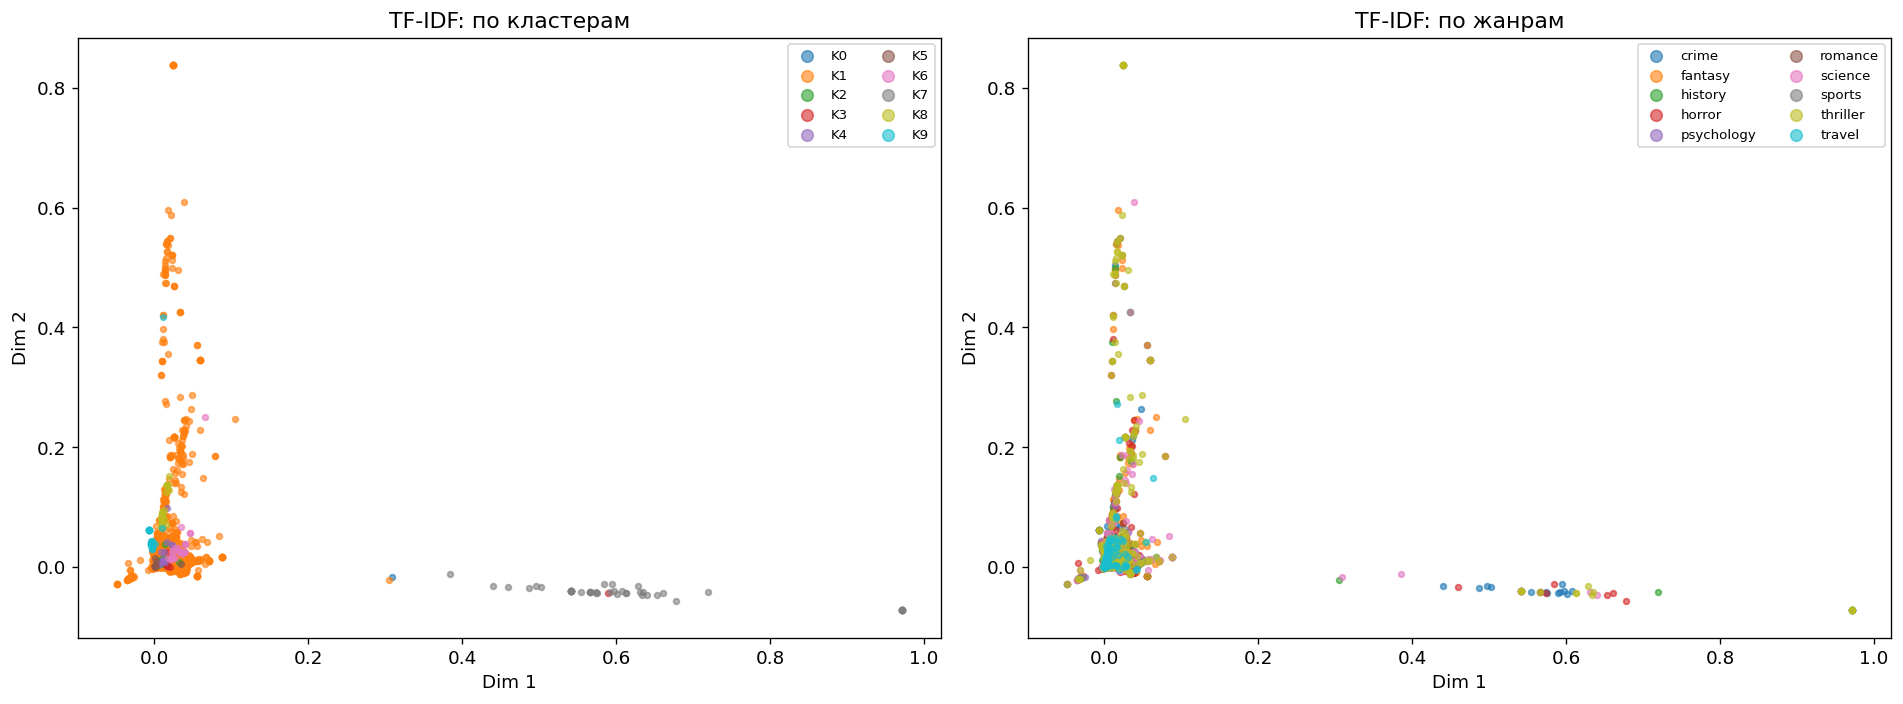

In [117]:
# Визуализация TF-IDF кластеров 
coords_tfidf = reduce_2d(X_tfidf, method='svd')
plot_clusters(coords_tfidf, labels_tfidf, genre_encoded,
              genre_names, title='TF-IDF')

In [118]:
# Сравнительная таблица метрик 
results = pd.DataFrame([
    {'Метод': 'CountVectorizer + KMeans',
     'Silhouette': round(sil_count, 4),
     'ARI': round(ari_count, 4)},
    {'Метод': 'TF-IDF + KMeans',
     'Silhouette': round(sil_tfidf, 4),
     'ARI': round(ari_tfidf, 4)},
])
results

,Метод,Silhouette,ARI
0,CountVectorizer + KMeans,0.0710,0.0000
1,TF-IDF + KMeans,0.0742,0.0019


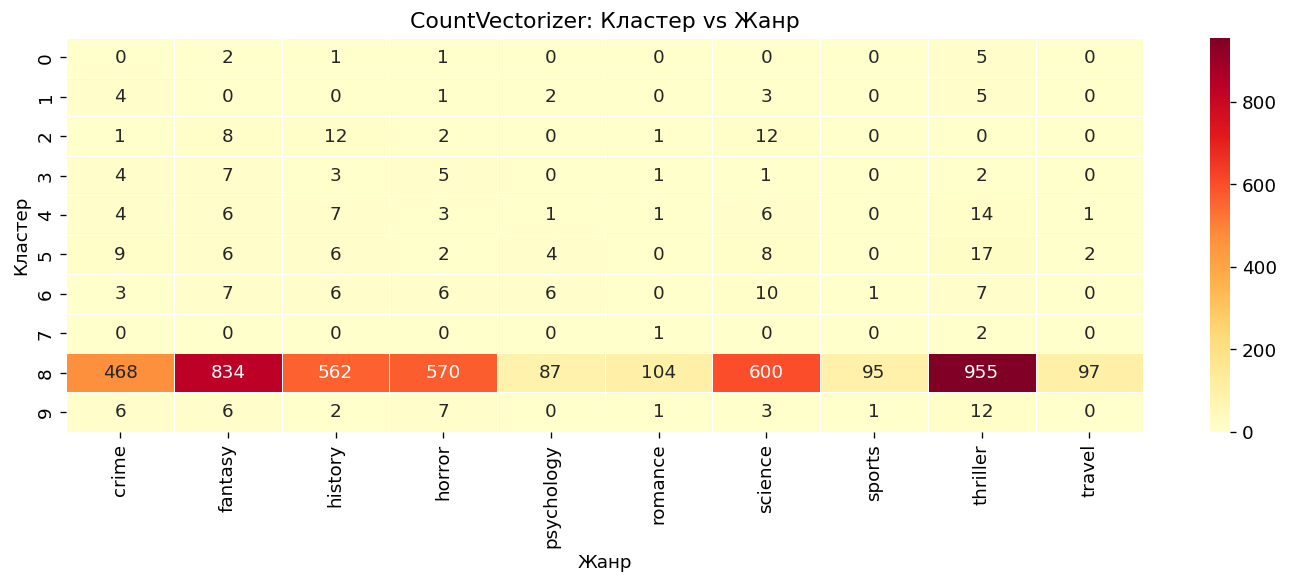

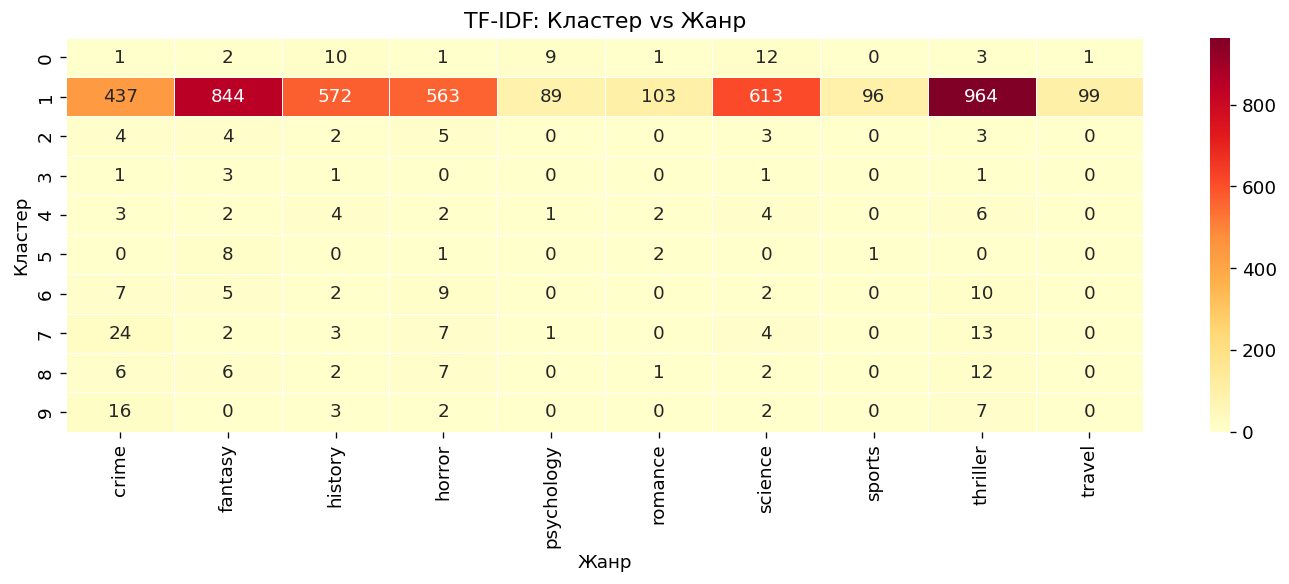

In [119]:
# тепловая карта 
def confusion_heatmap(cluster_labels, genre_labels, genre_names,
                      title='Кластер vs Жанр'):
    conf = pd.crosstab(
        pd.Series(cluster_labels, name='Кластер'),
        pd.Series([genre_names[g] for g in genre_labels], name='Жанр')
    )
    plt.figure(figsize=(12, 5))
    sns.heatmap(conf, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.5)
    plt.title(title)
    plt.tight_layout()
    plt.show()

confusion_heatmap(labels_count, genre_encoded, genre_names,
                  'CountVectorizer: Кластер vs Жанр')
confusion_heatmap(labels_tfidf, genre_encoded, genre_names,
                  'TF-IDF: Кластер vs Жанр')

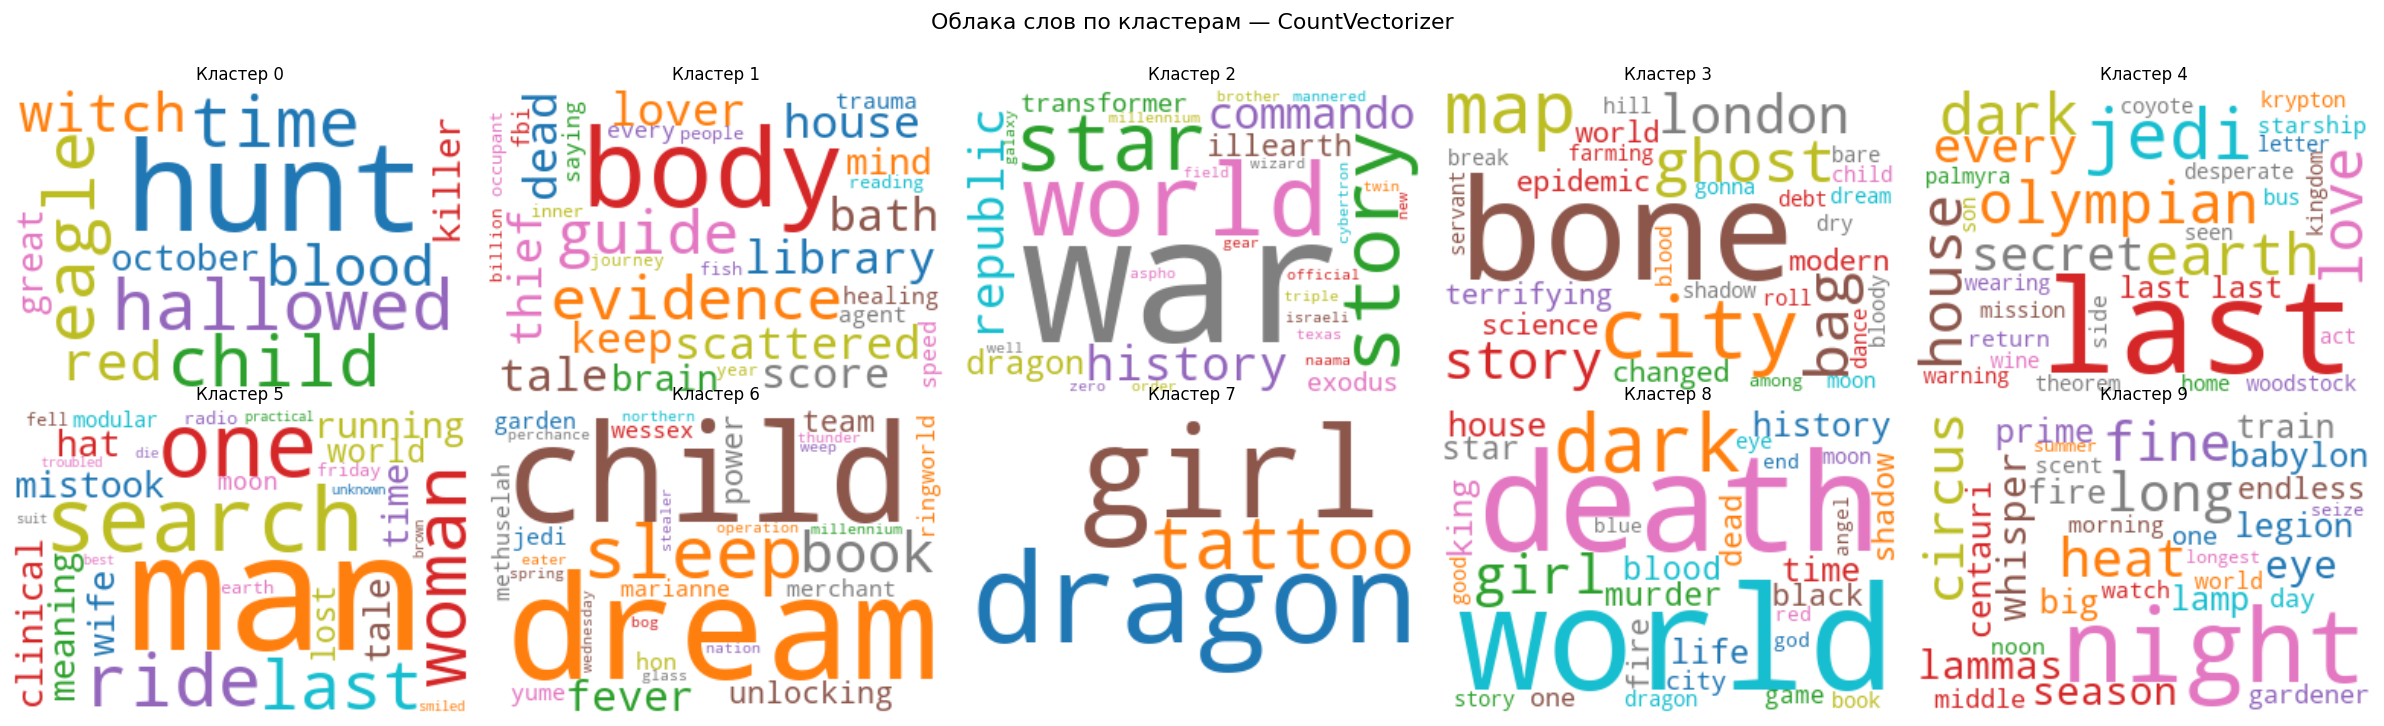

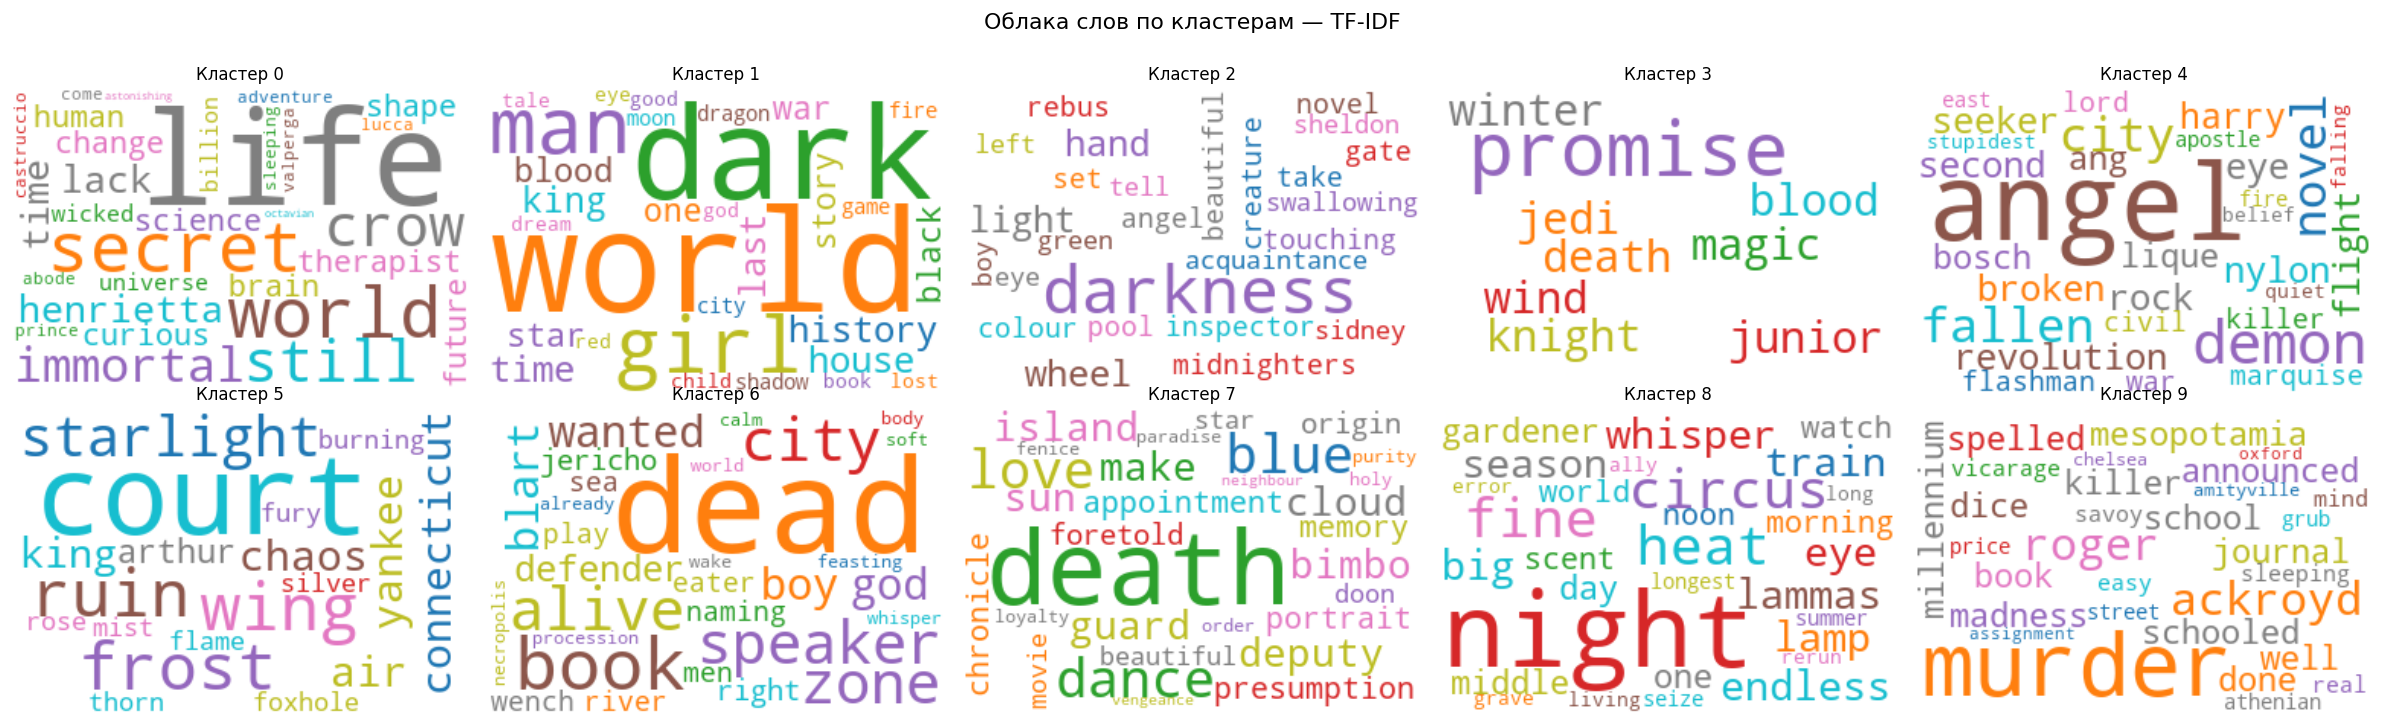

In [120]:
# Облака слов по кластерам 
for labels, title in [(labels_count, 'CountVectorizer'), 
                      (labels_tfidf, 'TF-IDF')]:
    n_cols = 5
    n_rows = (N_CLUSTERS + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
    axes = axes.flatten()

    df_clean['_tmp_label'] = labels
    for i in range(N_CLUSTERS):
        cluster_titles = ' '.join(
            df_clean.loc[df_clean['_tmp_label'] == i, 'title_clean']
        )
        if cluster_titles.strip():
            wc = WordCloud(width=300, height=200, background_color='white',
                           max_words=30, colormap='tab10').generate(cluster_titles)
            axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(f'Кластер {i}', fontsize=10)
        axes[i].axis('off')

    for j in range(N_CLUSTERS, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'Облака слов по кластерам — {title}', y=1.01)
    plt.tight_layout()
    plt.show()

df_clean.drop(columns=['_tmp_label'], inplace=True)

---
## Поиск лучшего сочетания метода и параметров; N-граммы

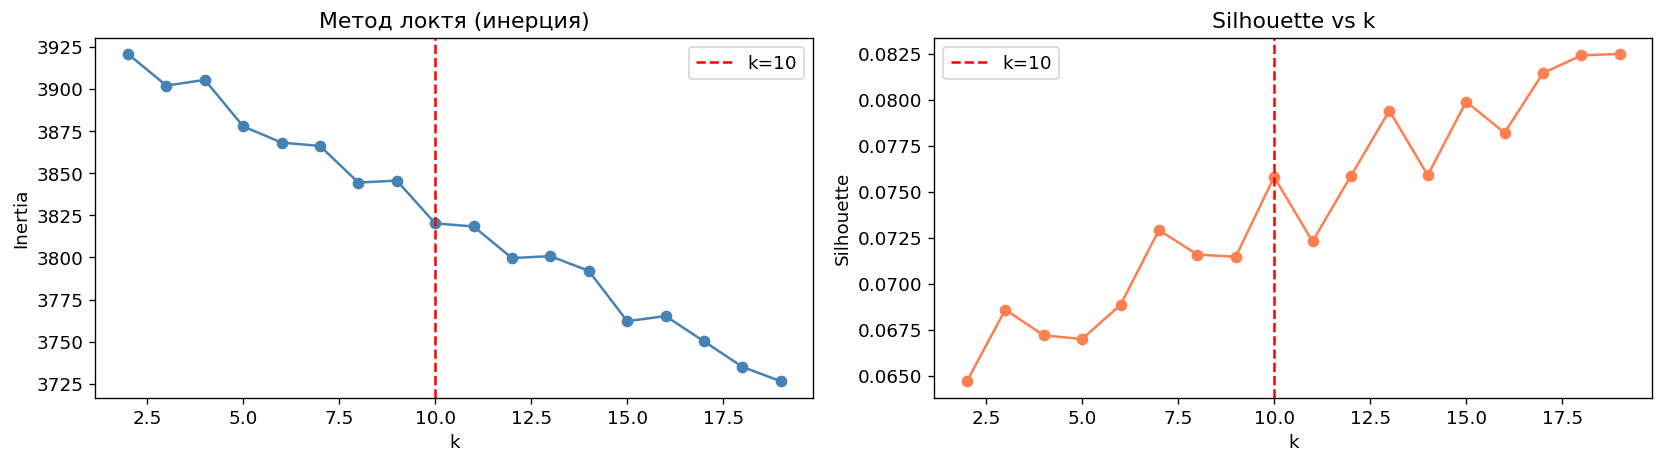

Лучший k по Silhouette: 19


In [121]:
inertias, sils = [], []
k_range = range(2, 20)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5, max_iter=200)
    lbl = km.fit_predict(X_tfidf)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_tfidf, lbl, sample_size=2000,
                                 random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(k_range), inertias, 'o-', color='steelblue')
axes[0].axvline(N_CLUSTERS, color='red', linestyle='--', label=f'k={N_CLUSTERS}')
axes[0].set(title='Метод локтя (инерция)', xlabel='k', ylabel='Inertia')
axes[0].legend()

axes[1].plot(list(k_range), sils, 'o-', color='coral')
axes[1].axvline(N_CLUSTERS, color='red', linestyle='--', label=f'k={N_CLUSTERS}')
axes[1].set(title='Silhouette vs k', xlabel='k', ylabel='Silhouette')
axes[1].legend()
plt.tight_layout()
plt.show()

best_k_sil = list(k_range)[np.argmax(sils)]
print(f'Лучший k по Silhouette: {best_k_sil}')

In [122]:
# n-граммы

experiments = {
    'Unigram (1,1)': TfidfVectorizer(ngram_range=(1, 1), max_features=5000,
                                     min_df=2, sublinear_tf=True),
    'Bigram  (1,2)': TfidfVectorizer(ngram_range=(1, 2), max_features=8000,
                                     min_df=2, sublinear_tf=True),
    'Trigram (1,3)': TfidfVectorizer(ngram_range=(1, 3), max_features=10000,
                                     min_df=2, sublinear_tf=True),
    'Char ngram (3,5)': TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5),
                                        max_features=8000, min_df=2),
}

exp_results = []
for name, vec in experiments.items():
    X_exp = vec.fit_transform(df_clean['title_clean'])
    for k in [N_CLUSTERS, best_k_sil]:
        km_exp = KMeans(n_clusters=k, random_state=RANDOM_STATE,
                        n_init=10, max_iter=300)
        lbl_exp = km_exp.fit_predict(X_exp)
        sil = silhouette_score(X_exp, lbl_exp, sample_size=2000,
                               random_state=RANDOM_STATE)
        ari = adjusted_rand_score(genre_encoded, lbl_exp)
        exp_results.append({'Метод': name, 'k': k,
                             'Silhouette': round(sil, 4),
                             'ARI': round(ari, 4)})

df_exp = pd.DataFrame(exp_results)
df_exp.sort_values('Silhouette', ascending=False)

,Метод,k,Silhouette,ARI
1,"Unigram (1,1)",19,0.0825,0.0024
5,"Trigram (1,3)",19,0.0772,0.0013
3,"Bigram (1,2)",19,0.0770,0.0014
0,"Unigram (1,1)",10,0.0758,0.0019
2,"Bigram (1,2)",10,0.0715,0.0017
4,"Trigram (1,3)",10,0.0713,0.0016
7,"Char ngram (3,5)",19,0.0235,-0.0004
6,"Char ngram (3,5)",10,0.0128,0.0049


In [123]:
#  Лучшая конфигурация (по результатам таблицы) 

best_vec = TfidfVectorizer(ngram_range=(1, 2), max_features=8000,
                           min_df=2, sublinear_tf=True)
X_best = best_vec.fit_transform(df_clean['title_clean'])

best_k = best_k_sil  
km_best = KMeans(n_clusters=best_k, random_state=RANDOM_STATE,
                 n_init=15, max_iter=500)
labels_best = km_best.fit_predict(X_best)

sil_best = silhouette_score(X_best, labels_best, sample_size=3000,
                             random_state=RANDOM_STATE)
ari_best = adjusted_rand_score(genre_encoded, labels_best)
print(f'Лучшая конфигурация — TF-IDF (1,2), k={best_k}')
print(f'Silhouette: {sil_best:.4f}  |  ARI: {ari_best:.4f}')

top_best = top_terms_per_cluster(best_vec, km_best, n_terms=10)
for k, words in top_best.items():
    print(f'  Кластер {k:2d}: {", ".join(words)}')

Лучшая конфигурация — TF-IDF (1,2), k=19
Silhouette: 0.0801  |  ARI: 0.0014
  Кластер  0: eagle, strike, conquest, cage, bronze, ninth, flight, wing, hunt, sand
  Кластер  1: girl, dark, world, night, dead, blood, star, time, last, war
  Кластер  2: king, raven king, raven, king men, future king, daughter, magician king, clash king, clash, magician
  Кластер  3: child, wednesday, ringworld, dear, nation, garden, jedi, hunt, perfect, home
  Кластер  4: wizard, wizard glass, glass, wonderland, large, war, rule, first, four, four season
  Кластер  5: man, running, last man, last, nazareth, radio, reaper, invisible, friday, vanished
  Кластер  6: house, black house, hell house, ninth house, house leaf, leaf, ninth, last house, hell, black
  Кластер  7: memory, false, apocalypse, light, dream, man, death, smart, many, friend
  Кластер  8: ring, brown, postman, always, starr, lucky, saturn, girl, fun inside, freedom
  Кластер  9: woman, true, cabin, fifth, library, black, portrait, story, co

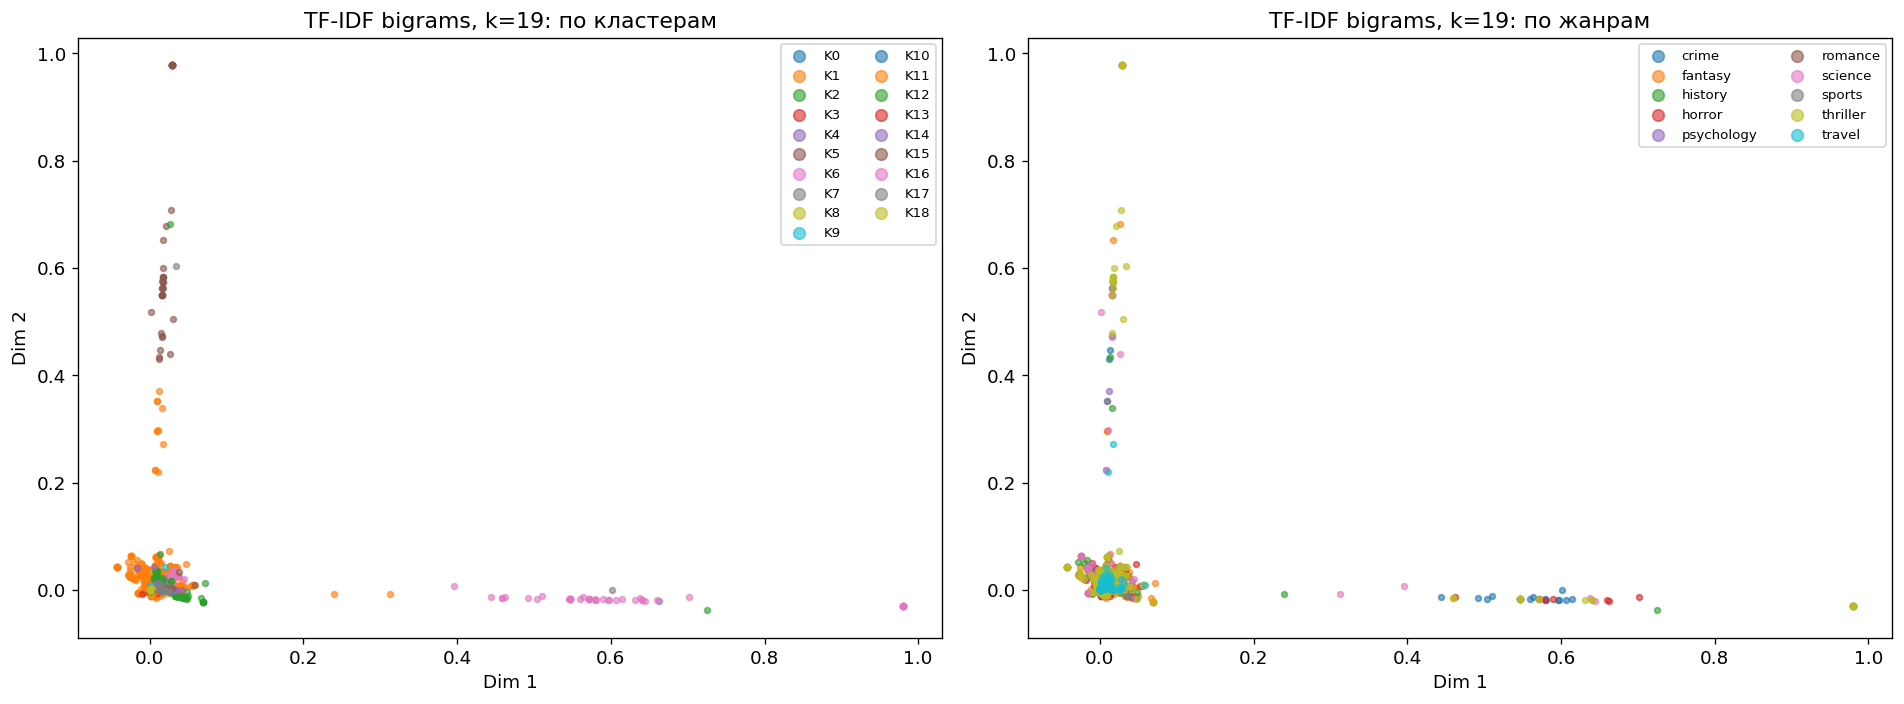

In [124]:
coords_best = reduce_2d(X_best, method='svd')
plot_clusters(coords_best, labels_best, genre_encoded,
              genre_names, title=f'TF-IDF bigrams, k={best_k}')

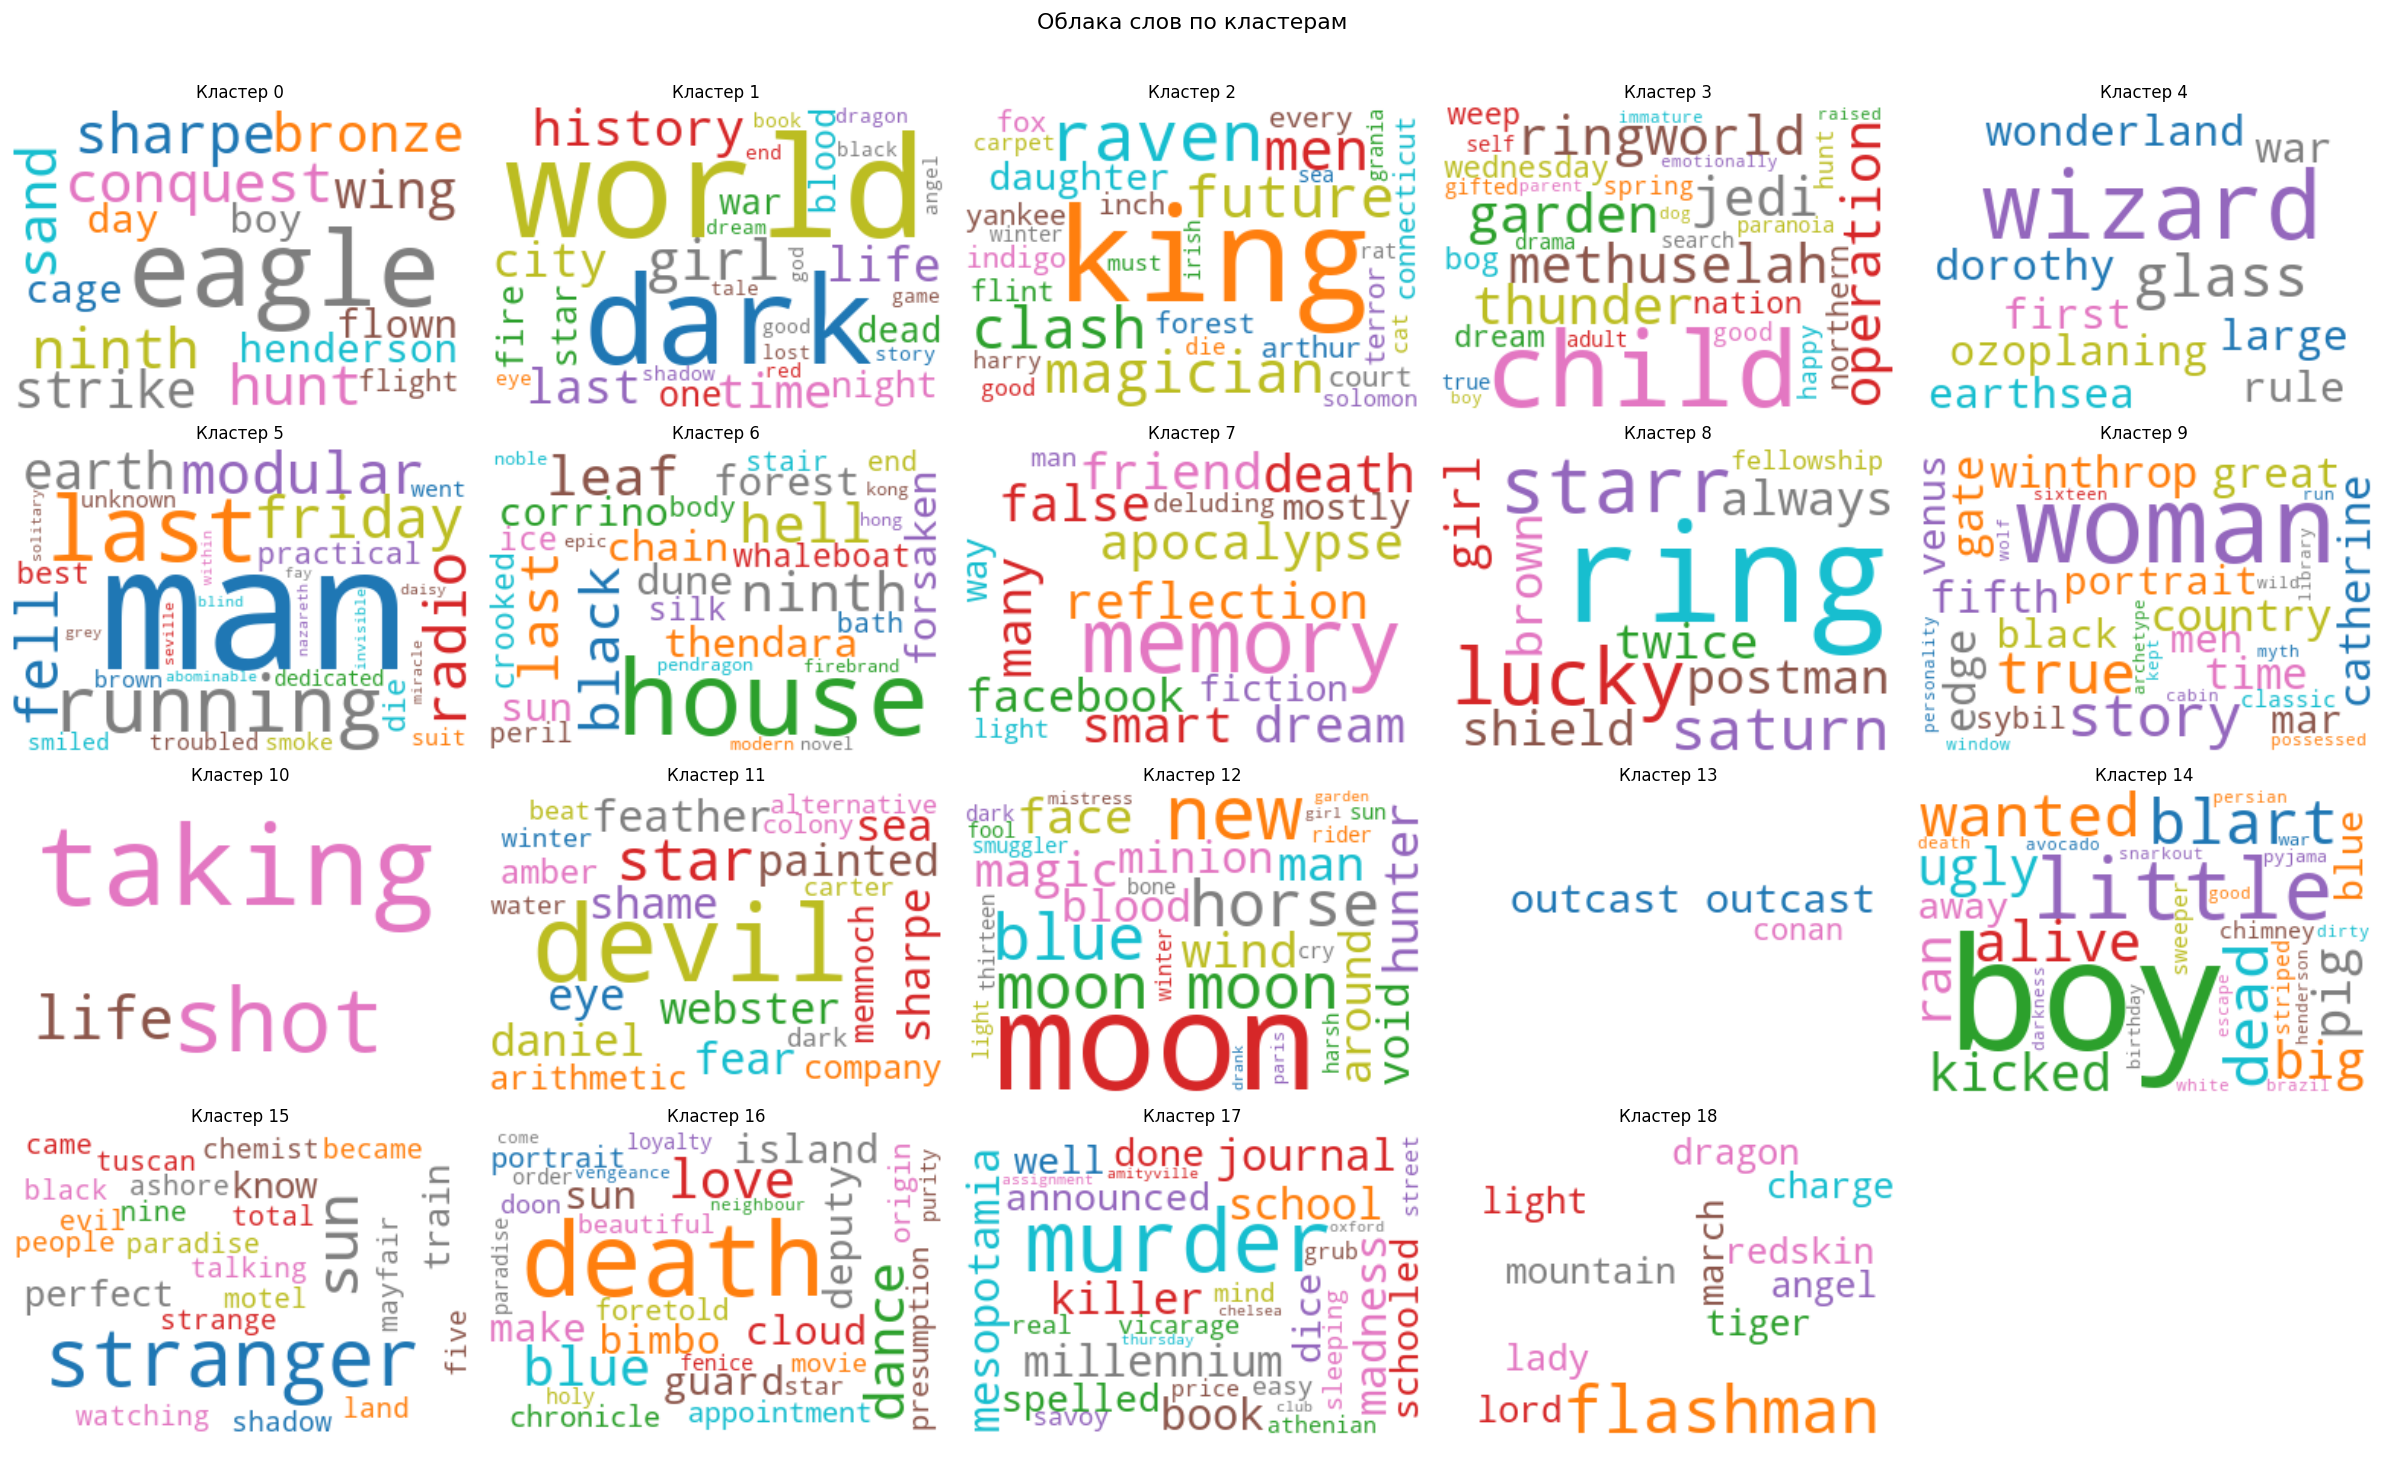

In [125]:
df_clean['cluster_best'] = labels_best
n_cols = 5
n_rows = (best_k + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.flatten()

for i in range(best_k):
    cluster_titles = ' '.join(
        df_clean.loc[df_clean['cluster_best'] == i, 'title_clean']
    )
    if cluster_titles.strip():
        wc = WordCloud(width=300, height=200, background_color='white',
                       max_words=30, colormap='tab10').generate(cluster_titles)
        axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f'Кластер {i}', fontsize=10)
    axes[i].axis('off')

for j in range(best_k, len(axes)):
    axes[j].axis('off')

plt.suptitle('Облака слов по кластерам', y=1.01)
plt.tight_layout()
plt.show()

---
## (*) Кластеризация по кратким содержаниям (summary)

In [126]:
def clean_summary(text: str) -> str:
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

df_sum = df_clean.dropna(subset=[summary_col]).copy()
df_sum['summary_clean'] = df_sum[summary_col].apply(clean_summary)
df_sum = df_sum[df_sum['summary_clean'].str.strip().str.len() > 0].reset_index(drop=True)

genre_enc_sum = le.transform(df_sum[genre_col])

print(f'Строк для кластеризации по summary: {len(df_sum)}')
print('Длина summary (слова):')
print(df_sum['summary_clean'].str.split().str.len().describe().round(1))

Строк для кластеризации по summary: 4638
Длина summary (слова):
count    4638.0
mean      195.2
std       232.6
min         1.0
25%        66.0
50%       106.0
75%       237.0
max      2930.0
Name: summary_clean, dtype: float64


In [ ]:
if summary_col in df_clean.columns:
    tfidf_sum = TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=20000,   
        min_df=3,
        max_df=0.85,
        sublinear_tf=True
    )
    X_sum = tfidf_sum.fit_transform(df_sum['summary_clean'])
    print(f'Матрица summary: {X_sum.shape}')

    km_sum = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE,
                    n_init=10, max_iter=300)
    labels_sum = km_sum.fit_predict(X_sum)

    sil_sum = silhouette_score(X_sum, labels_sum, sample_size=3000,
                                random_state=RANDOM_STATE)
    ari_sum = adjusted_rand_score(genre_enc_sum, labels_sum)

    print(f'\n=== Summary TF-IDF + KMeans ===')
    print(f'Silhouette: {sil_sum:.4f}  |  ARI: {ari_sum:.4f}')

    top_sum = top_terms_per_cluster(tfidf_sum, km_sum, n_terms=10)
    for k, words in top_sum.items():
        print(f'  Кластер {k:2d}: {", ".join(words)}')

Матрица summary: (4638, 20000)

=== Summary TF-IDF + KMeans ===
Silhouette: 0.0018  |  ARI: 0.1059
  Кластер  0: planet, earth, space, human, ship, alien, system, crew, year, time
  Кластер  1: find, take, one, back, tell, also, father, return, kill, two
  Кластер  2: less, life, one, year, know, love, new, secret, never, girl
  Кластер  3: novel, story, character, king, book, war, plot, set, life, roman
  Кластер  4: case, murder, detective, killer, police, investigation, crime, victim, found, body
  Кластер  5: book, world, history, science, human, life, time, classic, new, one
  Кластер  6: british, war, american, french, state, ship, soviet, president, united, force
  Кластер  7: find, one, new, story, man, begin, novel, life, book, also
  Кластер  8: novel concern, concern, novel, connecticut, alien, suburb, terran, transported, station, planet
  Кластер  9: less, world, power, magic, must, evil, dark, king, one, land


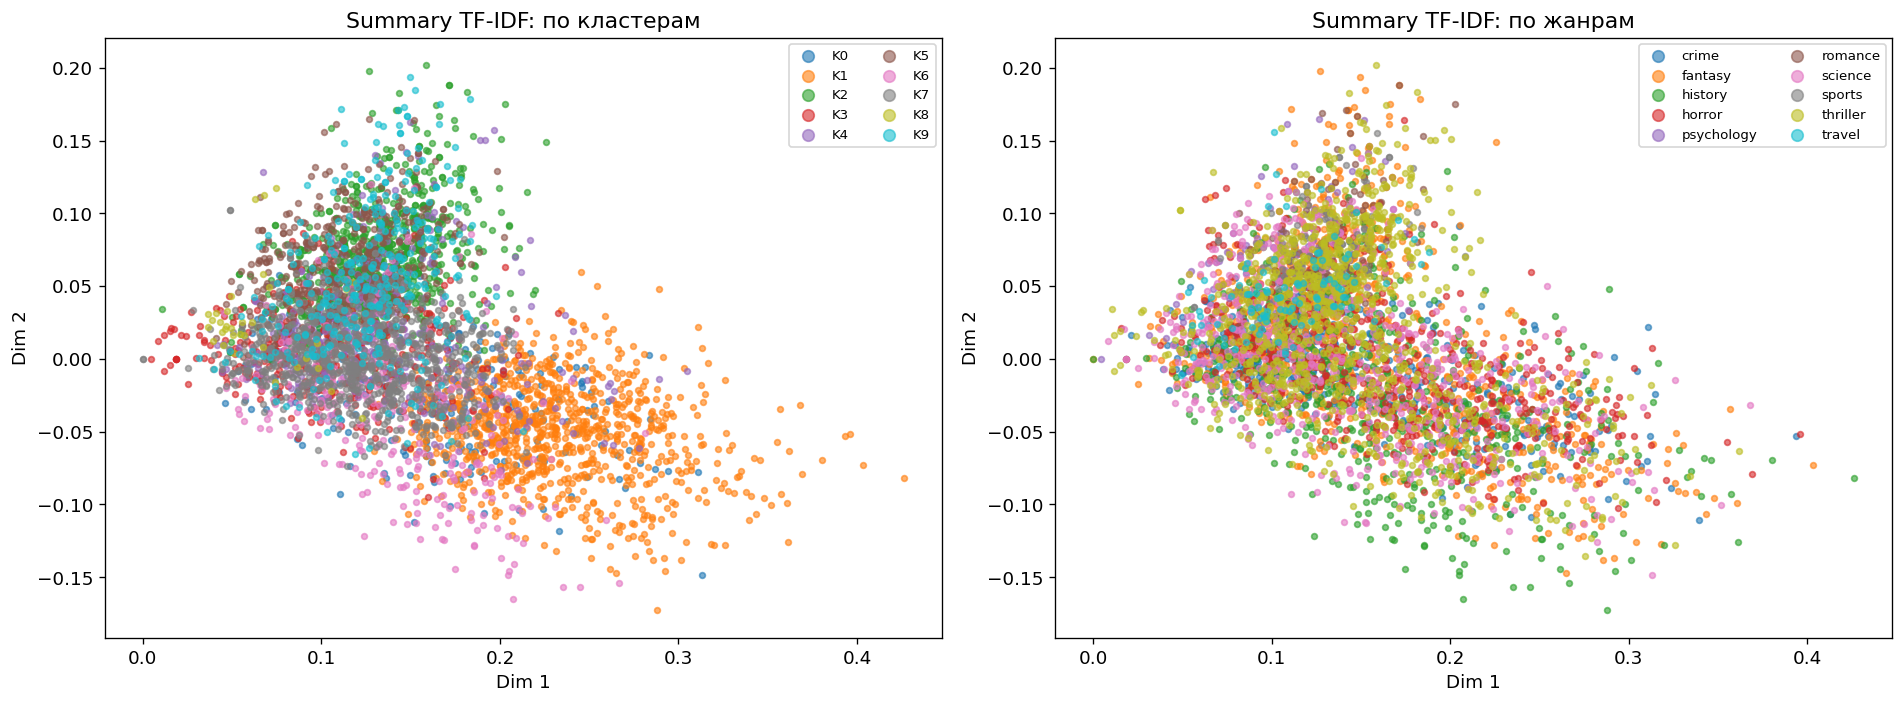

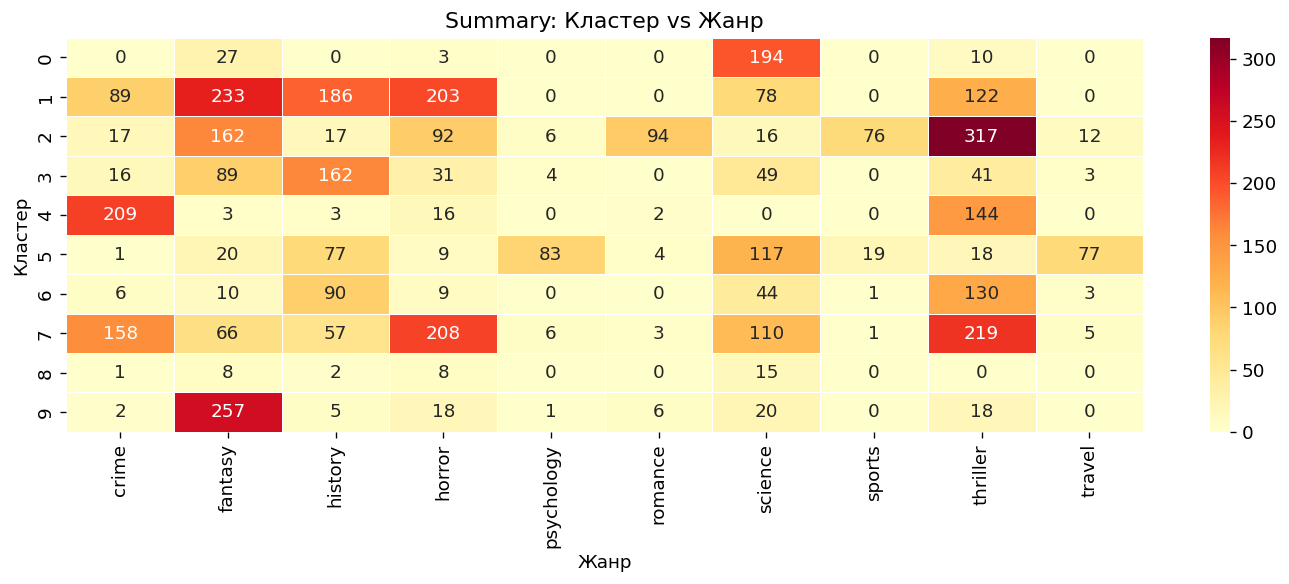

In [128]:
if summary_col in df_clean.columns:
    coords_sum = reduce_2d(X_sum, method='svd')
    plot_clusters(coords_sum, labels_sum, genre_enc_sum,
                  genre_names, title='Summary TF-IDF')
    confusion_heatmap(labels_sum, genre_enc_sum, genre_names,
                      'Summary: Кластер vs Жанр')

In [ ]:
rows = [
    {'Подход': 'Title + Count (1,1)',  'k': N_CLUSTERS,
     'Silhouette': round(sil_count, 4), 'ARI': round(ari_count, 4)},
    {'Подход': 'Title + TF-IDF (1,1)', 'k': N_CLUSTERS,
     'Silhouette': round(sil_tfidf, 4), 'ARI': round(ari_tfidf, 4)},
    {'Подход': f'Title + TF-IDF (1,2)', 'k': best_k,
     'Silhouette': round(sil_best, 4), 'ARI': round(ari_best, 4)},
]
if summary_col in df_clean.columns:
    rows.append({'Подход': 'Summary + TF-IDF (1,2)', 'k': N_CLUSTERS,
                 'Silhouette': round(sil_sum, 4), 'ARI': round(ari_sum, 4)})

final_df = pd.DataFrame(rows)
final_df

,Подход,k,Silhouette,ARI
0,"Title + Count (1,1)",10,0.0710,0.0000
1,"Title + TF-IDF (1,1)",10,0.0742,0.0019
2,"Title + TF-IDF (1,2)",19,0.0801,0.0014
3,"Summary + TF-IDF (1,2)",10,0.0018,0.1059
